# Fig. 1A: pipeline example cell (skeleton, flat skeleton, features)

Moved from `eyewire2-morphological-clustering/notebooks/manuscript/ew2-pipeline.ipynb`. That
notebook read the skeletons and the pre-computed features from the DataJoint database; this
version works from the exported SWC instead, so it needs no database:

- **Flat skeleton**: the warped SWC (`<cell>.swc`, z in SAC-normalized µm).
- **Raw skeleton**: optional, only drawn if `RAW_SWC` exists (the un-warped SWC is not in the dataset).
- **Features**: the polar density used in the paper (`polar_dens_id=1` in `density_polar.py`:
  centre = soma, measure = length, dendrites only, r in 25 x 10 µm bins, θ in 16 bins,
  z in 80 x 0.5 µm bins) is recomputed from the SWC. The old xyz density map is replaced by
  **z profile + r vs θ**.

The dropped DB-only cells were the schema ERD and the `FeaturesZ/FeaturesXY.plot1()` previews.

# Imports

In [1]:
import os
import sys

import numpy as np
import skeliner as sk
from matplotlib import pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from pywarper.warpers import segment_lengths

sys.path.append("../utils")

import data_io
from colors import cellclass2color
from style import set_rc_params

set_rc_params()

[Info] scikit-sparse not found. Falling back to scipy.sparse.linalg.spsolve.


# Settings

In [2]:
CELL_ID = 720575940575066105
SWC = f"{CELL_ID}.swc"  # flat (warped) skeleton
RAW_SWC = f"{CELL_ID}_raw.swc"  # un-warped skeleton; the raw panels are skipped if missing

# SAC bands in z (layer_name.py in eyewire2-datajoint)
Z_ON_SAC, Z_OFF_SAC = 0.0, 12.0
ON_COLOR, OFF_COLOR = cellclass2color["ON SAC"], cellclass2color["OFF SAC"]
CELL_COLOR = cellclass2color["RGC"]

# Bin edges of polar_dens_id=1 (eyewire2-datajoint morph_schema_config.yaml)
R_EDGES = np.arange(0, 250.1, 10)
T_EDGES = np.linspace(-np.pi, np.pi, 17)
Z_EDGES = np.arange(-15.25, 25.001, 0.5)

# Plot windows (µm), as in the original notebook
XLIM, YLIM = (400, 800), (200, 600)

CMAP = LinearSegmentedColormap.from_list("white_red", ["white", CELL_COLOR, "#3b0000"])

config = data_io.get_data_config()
version = config.get("version", None)
fig_dir = f"../figures/examples/v{version}"
os.makedirs(fig_dir, exist_ok=True)

# Load skeleton(s)

In [3]:
assert os.path.isfile(SWC), f"Put the flat skeleton at {os.path.abspath(SWC)}"
skel_norm = sk.io.load_swc(SWC)
skel_norm.convert_unit("um")

skels = {"norm": skel_norm}
if RAW_SWC is not None and os.path.isfile(RAW_SWC):
    skel_raw = sk.io.load_swc(RAW_SWC)
    skel_raw.convert_unit("um")
    skels = {"raw": skel_raw, **skels}
else:
    print("No raw skeleton, skipping the raw panels")

# Skeleton panels (xz + xy)

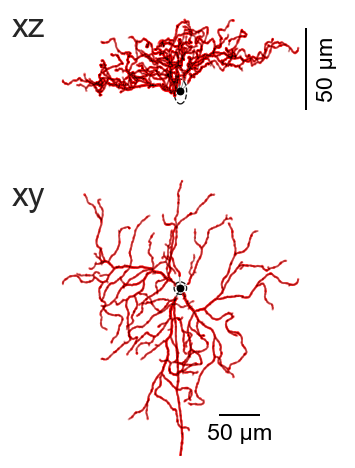

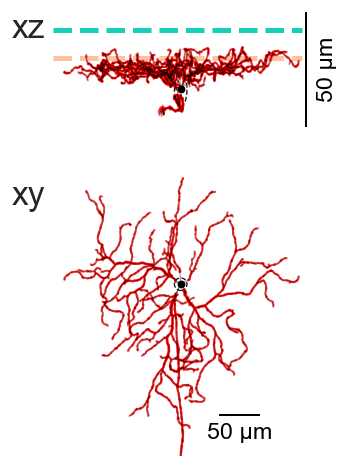

In [4]:
def scalebar_v(ax, x, y0, y1, label, label_x, label_y):
    ax.plot([x, x], [y0, y1], c="k", solid_capstyle="butt")
    ax.text(label_x, label_y, label, c="k", ha="center", rotation=90, va="center", fontsize=14)


for name, skel in skels.items():
    fig, axs = plt.subplots(2, 1, sharex=True, height_ratios=(1, 3), figsize=(3, 4))
    ax = axs[0]
    sk.plot.projection(skel, ax=ax, plane="xz")
    ax.set_aspect("auto", "box")
    if name == "raw":
        ax.set_ylim(0, 70)
        scalebar_v(ax, 755, 10, 60, "50 µm", 780, 35)
    else:
        ax.set_ylim(-30, 20)
        scalebar_v(ax, 755, -30, 20, "50 µm", 780, -5)
        ax.plot([450, 750], [Z_ON_SAC] * 2, c=ON_COLOR, ls="--", lw=3, zorder=-10)
        ax.plot([450, 750], [Z_OFF_SAC] * 2, c=OFF_COLOR, ls="--", lw=3, zorder=-10)
    ax.set_xlim(*XLIM)
    ax.set_title("xz", loc="left", y=0.9, va="top", fontsize=20)
    ax.set(xticks=[], yticks=[], xlabel=None, ylabel=None)
    ax.axis("off")

    ax = axs[1]
    ax.set_title("xy", loc="left", y=0.8, va="top", fontsize=20)
    sk.plot.projection(skel, ax=ax, plane="xy")
    ax.set_aspect("equal", "box")
    ax.set_xlim(*XLIM)
    ax.set_ylim(*YLIM)
    ax.plot([650, 700], [250, 250], c="k", solid_capstyle="butt")
    ax.text(675, 220, "50 µm", c="k", ha="center", fontsize=14)
    ax.set(xticks=[], yticks=[], xlabel=None, ylabel=None)
    ax.axis("off")

    plt.tight_layout()
    for ext in ("png", "svg"):
        fig.savefig(f"{fig_dir}/pipeline_example_{name}_skel.{ext}", dpi=450, transparent=True)
    plt.show()

# Features: polar density from the flat skeleton

Same computation as `get_xyz_profile(coordinate_system="polar", center="soma", measure="length",
blur_sigma=0)` in `eyewire2_datajoint.utils.xyz` (small enough to duplicate here instead of
adding a repo dependency): cable length per edge, binned at the edge midpoint in
(r, θ, z) around the soma, dendrite nodes only. In the exported SWC the soma is type 1, the
axon (set by `detect_axon` in the pipeline) type 2, and everything else dendrite, so
"dendrites" = all nodes that are neither soma nor axon.

In [5]:
def polar_histogram(skel, r_edges, t_edges, z_edges):
    """Cable length per (r, θ, z) bin around the soma; returns an array of shape (Nr, Nt, Nz)."""
    length, mid = segment_lengths(skel)
    keep = ~np.isin(skel.ntype, (1, 2)) & (mid[:, 2] >= z_edges[0]) & (mid[:, 2] <= z_edges[-1])
    mid, length = mid[keep], length[keep]

    cx, cy = skel.soma.center[:2]
    dx, dy = mid[:, 0] - cx, mid[:, 1] - cy
    polar = np.column_stack([np.hypot(dx, dy), np.arctan2(dy, dx), mid[:, 2]])
    hist, _ = np.histogramdd(polar, bins=[r_edges, t_edges, z_edges], weights=length)
    return hist


hist = polar_histogram(skel_norm, R_EDGES, T_EDGES, Z_EDGES)
print(f"{hist.sum():.0f} µm of dendritic cable in the bins")

z_profile = hist.sum(axis=(0, 1)) / hist.sum()  # (Nz,), normalized like polar_dens_z
r_theta = hist.sum(axis=2)  # (Nr, Nt)
z_centers = (Z_EDGES[:-1] + Z_EDGES[1:]) / 2

# Crop r to where the cell has mass (the 250 µm range is far larger than most RGCs)
R_MASS = 0.995
cum_r = np.cumsum(hist.sum(axis=(1, 2))) / hist.sum()
R_MAX = R_EDGES[min(int(np.searchsorted(cum_r, R_MASS)) + 1, len(R_EDGES) - 1)]
print(f"{R_MAX=}")

4703 µm of dendritic cable in the bins
R_MAX=np.float64(170.0)


# Features panel: z profile + r vs θ

Styled like the original panel: thick dark-red profile with the dashed ON / OFF SAC bands on
top, density map below, no axes, same figure size, transparent background.

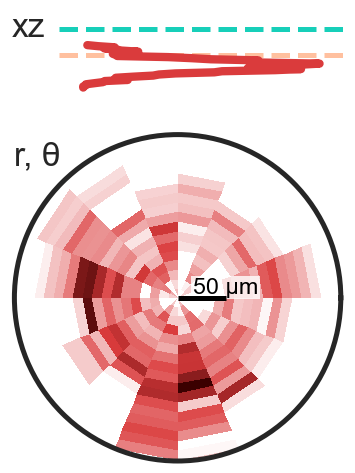

In [6]:
fig, axs = plt.subplots(2, 1, height_ratios=(1, 3), figsize=(3, 4))

ax = axs[0]
vmax = z_profile.max()
ax.set_ylim(-30, 20)
ax.set_xlim(-0.3 * vmax, vmax * 1.1)
ax.plot([-0.1 * vmax, vmax * 1.1], [Z_ON_SAC] * 2, c=ON_COLOR, ls="--", lw=3)
ax.plot([-0.1 * vmax, vmax * 1.1], [Z_OFF_SAC] * 2, c=OFF_COLOR, ls="--", lw=3)
occupied = np.where(z_profile > 0)[0]  # don't draw the empty bins outside the cell as a line at 0
sl = slice(occupied[0], occupied[-1] + 1)
ax.plot(z_profile[sl], z_centers[sl], c=CELL_COLOR, lw=5)
ax.set_title("xz", loc="left", y=0.9, va="top", fontsize=20)
ax.set(xticks=[], yticks=[], xlabel=None, ylabel=None)
ax.axis("off")

# r vs θ: polar axes in the slot of the old xy density map
axs[1].remove()
ax = fig.add_subplot(2, 1, 2, projection="polar")
Theta, R = np.meshgrid(T_EDGES, R_EDGES)
ax.pcolormesh(Theta, R, r_theta, cmap=CMAP, vmin=0, shading="flat", rasterized=True)
ax.set_theta_zero_location("E")
ax.set_ylim(0, R_MAX)
ax.set_xticks([])
ax.set_yticks([])
ax.grid(False)
ax.spines["polar"].set_linewidth(3)
ax.set_title("r, θ", loc="left", y=0.95, va="top", fontsize=20)
# radial scale bar along the θ = 0 axis
ax.plot([0, 0], [0, 50], c="k", lw=3, solid_capstyle="butt", zorder=5)
ax.text(0, 50, "50 µm", c="k", ha="center", va="bottom", fontsize=14,
        bbox=dict(fc="white", ec="none", pad=1, alpha=0.8))

plt.tight_layout()
for ext in ("png", "svg"):
    fig.savefig(f"{fig_dir}/pipeline_example_features.{ext}", dpi=450, transparent=True)
plt.show()